In [1]:
!pip install -q ultralytics pyyaml
import os, glob, shutil, random, hashlib, time, math, warnings, yaml
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt, seaborn as sns
import xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

INPUT_DIR = "/kaggle/input"
WORK      = "/kaggle/working"
OUT       = f"{WORK}/pothole_yolo"
IMG_EXT   = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

IMG_MAX             = 640    # resize: long side 640 (aspect ratio preserved)
MIN_BOX_PX          = 4      # chhote invalid boxes hata do
NEAR_DUP_HAMMING    = 2      # near-duplicate threshold (64-bit dHash)
MERGE_TO_SINGLE_CLASS = True # project = pothole detection, sab classes -> "pothole"

print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

GPU: True Tesla T4


In [2]:
imgs, xmls, txts, yamls = {}, {}, {}, []
stem_collisions = 0
for p in Path(INPUT_DIR).rglob("*"):
    if not p.is_file(): continue
    e = p.suffix.lower()
    if e in IMG_EXT:
        if p.stem in imgs: stem_collisions += 1
        imgs[p.stem] = str(p)
    elif e == ".xml": xmls[p.stem] = str(p)
    elif e == ".txt" and p.stem.lower() not in ("classes", "labels", "readme", "requirements"):
        txts[p.stem] = str(p)
    elif e in (".yaml", ".yml"): yamls.append(str(p))

print(f"images={len(imgs)} xml={len(xmls)} txt={len(txts)} yaml={yamls} stem_collisions={stem_collisions}")
assert len(imgs) > 0, "Koi image nahi mili: Add Input > Datasets se pothole dataset add karein."

# folder tree (2 levels)
for d in sorted(Path(INPUT_DIR).glob("*"))[:5]:
    print(d)
    for s in sorted(d.glob("*"))[:8]: print("   ", s.name)

LABEL_FORMAT = "xml" if len(xmls) >= len(txts) else "txt"
LABELS = xmls if LABEL_FORMAT == "xml" else txts
print("Label format detected:", LABEL_FORMAT, "| labels:", len(LABELS))

YAML_NAMES = {}
for y in yamls:
    try:
        n = yaml.safe_load(open(y)).get("names")
        if n:
            YAML_NAMES = dict(enumerate(n)) if isinstance(n, list) else {int(k): v for k, v in n.items()}
            print("Class names from", y, "->", YAML_NAMES); break
    except Exception: pass

images=2083 xml=0 txt=2084 yaml=['/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/data.yaml'] stem_collisions=0
/kaggle/input/datasets
    rajdalsaniya
Label format detected: txt | labels: 2084
Class names from /kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/data.yaml -> {0: 'pothole'}


In [3]:
def parse_xml(path):
    r = ET.parse(path).getroot()
    sz = r.find("size")
    xml_wh = (int(float(sz.findtext("width", 0))), int(float(sz.findtext("height", 0)))) if sz is not None else (0, 0)
    out = []
    for o in r.findall("object"):
        b = o.find("bndbox")
        try: x1, y1, x2, y2 = [float(b.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]
        except Exception: continue
        out.append((o.findtext("name", "").strip().lower(), x1, y1, x2, y2))
    return xml_wh, out

def parse_txt(path, W, H):
    out = []
    for line in open(path).read().strip().splitlines():
        v = line.split()
        if len(v) < 5: continue
        try: c = int(float(v[0])); nums = list(map(float, v[1:]))
        except Exception: continue
        if len(nums) == 4: xc, yc, w, h = nums
        else:  # polygon -> bbox
            xs, ys = nums[0::2], nums[1::2]
            xc, yc = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2; w, h = max(xs)-min(xs), max(ys)-min(ys)
        out.append((str(YAML_NAMES.get(c, c)).lower(), (xc-w/2)*W, (yc-h/2)*H, (xc+w/2)*W, (yc+h/2)*H))
    return out

rows, boxes, DH = [], [], {}
for stem, path in tqdm(imgs.items(), desc="Validating images"):
    r = dict(stem=stem, path=path, ok=True, W=0, H=0, has_label=stem in LABELS, size_mismatch=False)
    try:
        with Image.open(path) as im: im.verify()
        im = cv2.imread(path)
        if im is None: raise ValueError("unreadable")
        H, W = im.shape[:2]; r.update(W=W, H=H)
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        r["blur"] = cv2.Laplacian(g, cv2.CV_64F).var()
        r["brightness"] = float(g.mean())
        r["md5"] = hashlib.md5(open(path, "rb").read()).hexdigest()
        s = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
        DH[stem] = (s[:, 1:] > s[:, :-1]).flatten()
        if r["has_label"]:
            if LABEL_FORMAT == "xml":
                (xw, xh), objs = parse_xml(LABELS[stem])
                if xw and xh and (xw, xh) != (W, H):       # EXIF / resize mismatch -> scale boxes
                    r["size_mismatch"] = True
                    objs = [(n, a*W/xw, b*H/xh, c*W/xw, d*H/xh) for n, a, b, c, d in objs]
            else:
                objs = parse_txt(LABELS[stem], W, H)
            for n, x1, y1, x2, y2 in objs: boxes.append(dict(stem=stem, cls=n, x1=x1, y1=y1, x2=x2, y2=y2))
    except Exception as e:
        r["ok"] = False; r["err"] = str(e)
    rows.append(r)

df_img = pd.DataFrame(rows); df_box = pd.DataFrame(boxes)
print(df_img.ok.value_counts().to_dict(), "| boxes parsed:", len(df_box))
print("Class names found:\n", df_box.cls.value_counts())

Validating images:   0%|          | 0/2083 [00:00<?, ?it/s]

{True: 2083} | boxes parsed: 4246
Class names found:
 cls
pothole    4246
Name: count, dtype: int64


            W       H      blur  brightness
count  2083.0  2083.0   2083.00     2083.00
mean    640.0   640.0  11664.32      117.82
std       0.0     0.0   6545.28       48.81
min     640.0   640.0     19.20        8.04
25%     640.0   640.0   6264.92       80.04
50%     640.0   640.0  11841.52      118.54
75%     640.0   640.0  17073.11      155.73
max     640.0   640.0  28162.14      230.29
Images: 2083 | with label file: 2083 | boxes: 4246


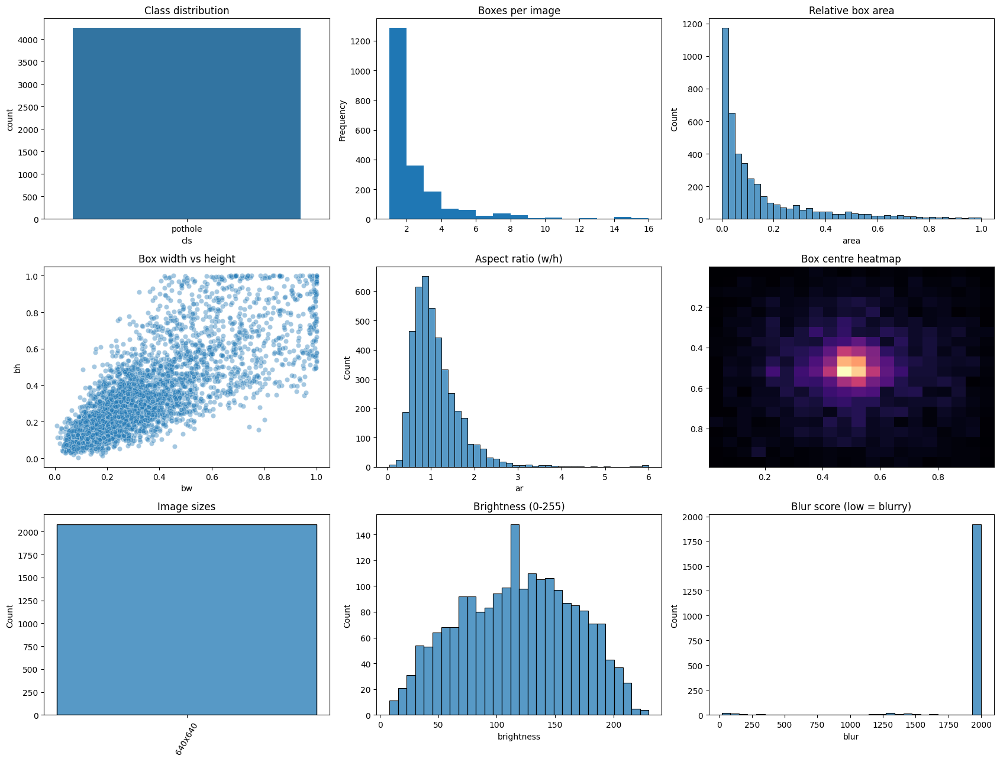

area
large >5%      2428
medium 1-5%    1349
small <1%       469
Name: count, dtype: int64


In [4]:
ok = df_img[df_img.ok].copy()
b = df_box.merge(ok[["stem", "W", "H"]], on="stem")
b["bw"] = (b.x2-b.x1)/b.W; b["bh"] = (b.y2-b.y1)/b.H
b["area"] = b.bw*b.bh; b["ar"] = (b.x2-b.x1)/(b.y2-b.y1+1e-9)
b["xc"] = (b.x1+b.x2)/2/b.W; b["yc"] = (b.y1+b.y2)/2/b.H

print(ok[["W", "H", "blur", "brightness"]].describe().round(2))
print("Images:", len(ok), "| with label file:", ok.has_label.sum(), "| boxes:", len(b))

fig, ax = plt.subplots(3, 3, figsize=(17, 13))
sns.countplot(x="cls", data=b, ax=ax[0,0]).set_title("Class distribution")
b.groupby("stem").size().plot.hist(bins=15, ax=ax[0,1], title="Boxes per image")
sns.histplot(b.area, bins=40, ax=ax[0,2]).set_title("Relative box area")
sns.scatterplot(x="bw", y="bh", data=b, alpha=.4, ax=ax[1,0]).set_title("Box width vs height")
sns.histplot(b.ar.clip(0, 6), bins=40, ax=ax[1,1]).set_title("Aspect ratio (w/h)")
h = ax[1,2].hist2d(b.xc, b.yc, bins=20, cmap="magma"); ax[1,2].invert_yaxis(); ax[1,2].set_title("Box centre heatmap")
sns.histplot(ok.W.astype(str)+"x"+ok.H.astype(str), ax=ax[2,0]).set_title("Image sizes"); ax[2,0].tick_params(axis="x", rotation=60)
sns.histplot(ok.brightness, bins=30, ax=ax[2,1]).set_title("Brightness (0-255)")
sns.histplot(ok.blur.clip(0, 2000), bins=30, ax=ax[2,2]).set_title("Blur score (low = blurry)")
plt.tight_layout(); plt.savefig(f"{WORK}/eda_summary.png", dpi=130); plt.show()

size_cat = pd.cut(b.area, [0, .01, .05, 1], labels=["small <1%", "medium 1-5%", "large >5%"])
print(size_cat.value_counts())

In [5]:
report = {}
df = df_img[df_img.ok].copy()
report["corrupt_removed"] = int((~df_img.ok).sum())

# Missing labels
report["missing_label_removed"] = int((~df.has_label).sum())
df = df[df.has_label]

# Exact duplicates
d = df.duplicated("md5", keep="first")
report["exact_dup_removed"] = int(d.sum()); df = df[~d]

# Near duplicates (video frames jaisi almost-same images -> data leakage se bachao)
stems = df.stem.tolist(); bits = np.stack([DH[s] for s in stems]); drop = set()
for i in range(len(stems)):
    if stems[i] in drop: continue
    dist = (bits[i+1:] != bits[i]).sum(1)
    drop.update(stems[i+1+j] for j in np.where(dist <= NEAR_DUP_HAMMING)[0])
report["near_dup_removed"] = len(drop); df = df[~df.stem.isin(drop)]

# Annotation verification
bx = df_box[df_box.stem.isin(df.stem)].merge(df[["stem", "W", "H"]], on="stem")
report["boxes_out_of_bounds_clipped"] = int(((bx.x1<0)|(bx.y1<0)|(bx.x2>bx.W)|(bx.y2>bx.H)).sum())
bx["x1"] = bx.x1.clip(0, bx.W); bx["x2"] = bx.x2.clip(0, bx.W)
bx["y1"] = bx.y1.clip(0, bx.H); bx["y2"] = bx.y2.clip(0, bx.H)
swapped = bx.x2 < bx.x1
report["swapped_coords"] = int(swapped.sum())
bx.loc[swapped, ["x1", "x2"]] = bx.loc[swapped, ["x2", "x1"]].values
bad = ((bx.x2-bx.x1) < MIN_BOX_PX) | ((bx.y2-bx.y1) < MIN_BOX_PX)
report["tiny_or_zero_boxes_removed"] = int(bad.sum()); bx = bx[~bad]
n = len(bx); bx = bx.round(1).drop_duplicates(["stem", "cls", "x1", "y1", "x2", "y2"])
report["duplicate_boxes_removed"] = n - len(bx)

# Class handling
if MERGE_TO_SINGLE_CLASS: bx["cls"] = "pothole"
CLASS_NAMES = sorted(bx.cls.unique()); CID = {n: i for i, n in enumerate(CLASS_NAMES)}
bx["cid"] = bx.cls.map(CID)
report["images_final"] = len(df); report["boxes_final"] = len(bx)
report["background_images(no box)"] = int((~df.stem.isin(bx.stem)).sum())
print(pd.Series(report)); print("Classes:", CLASS_NAMES)

# Imbalance check
cnt = bx.cid.value_counts().sort_index(); print("\nBoxes per class:\n", cnt)
IMBALANCED = len(cnt) > 1 and cnt.max()/cnt.min() > 3
print("Class imbalance (ratio>3):", IMBALANCED)

corrupt_removed                   0
missing_label_removed             0
exact_dup_removed                 6
near_dup_removed                  1
boxes_out_of_bounds_clipped       0
swapped_coords                    0
tiny_or_zero_boxes_removed        1
duplicate_boxes_removed           0
images_final                   2076
boxes_final                    4235
background_images(no box)         0
dtype: int64
Classes: ['pothole']

Boxes per class:
 cid
0    4235
Name: count, dtype: int64
Class imbalance (ratio>3): False


In [6]:
info = df.set_index("stem").to_dict("index")
grp = {s: g for s, g in bx.groupby("stem")}
stems = np.array(sorted(df.stem))

def dominant(s): return int(grp[s].cid.mode()[0]) if s in grp else -1
strat = np.array([dominant(s) for s in stems])
try:
    tr, tmp = train_test_split(stems, test_size=0.30, random_state=SEED, stratify=strat)
    va, te  = train_test_split(tmp, test_size=1/3, random_state=SEED, stratify=[dominant(s) for s in tmp])
except ValueError:
    tr, tmp = train_test_split(stems, test_size=0.30, random_state=SEED)
    va, te  = train_test_split(tmp, test_size=1/3, random_state=SEED)
print("train/val/test:", len(tr), len(va), len(te))

repeat = {}
if IMBALANCED:
    for s in tr:
        if s in grp:
            rare = min(grp[s].cid.unique(), key=lambda c: cnt[c])
            repeat[s] = min(math.ceil(cnt.max()/cnt[rare]), 3)
    print("Oversampled train images:", sum(v > 1 for v in repeat.values()))

train/val/test: 1453 415 208


In [7]:
shutil.rmtree(OUT, ignore_errors=True)

def write_split(name, split_stems):
    os.makedirs(f"{OUT}/images/{name}", exist_ok=True); os.makedirs(f"{OUT}/labels/{name}", exist_ok=True)
    for s in tqdm(split_stems, desc=name):
        r = info[s]; im = cv2.imread(r["path"]); W, H = r["W"], r["H"]
        sc = IMG_MAX / max(W, H)
        if sc < 1: im = cv2.resize(im, None, fx=sc, fy=sc, interpolation=cv2.INTER_AREA)
        lines = []
        if s in grp:
            for _, q in grp[s].iterrows():
                lines.append(f"{int(q.cid)} {(q.x1+q.x2)/2/W:.6f} {(q.y1+q.y2)/2/H:.6f} {(q.x2-q.x1)/W:.6f} {(q.y2-q.y1)/H:.6f}")
        for k in range(repeat.get(s, 1) if name == "train" else 1):
            fn = s if k == 0 else f"{s}_os{k}"
            cv2.imwrite(f"{OUT}/images/{name}/{fn}.jpg", im, [cv2.IMWRITE_JPEG_QUALITY, 95])
            open(f"{OUT}/labels/{name}/{fn}.txt", "w").write("\n".join(lines))

for n, sp in [("train", tr), ("val", va), ("test", te)]: write_split(n, sp)

YAML = f"{WORK}/data.yaml"
yaml.safe_dump({"path": OUT, "train": "images/train", "val": "images/val", "test": "images/test",
                "names": {i: n for i, n in enumerate(CLASS_NAMES)}}, open(YAML, "w"))
print(open(YAML).read())

train:   0%|          | 0/1453 [00:00<?, ?it/s]

val:   0%|          | 0/415 [00:00<?, ?it/s]

test:   0%|          | 0/208 [00:00<?, ?it/s]

names:
  0: pothole
path: /kaggle/working/pothole_yolo
test: images/test
train: images/train
val: images/val



train 1453 images OK
val 415 images OK
test 208 images OK
Invalid label lines: 0


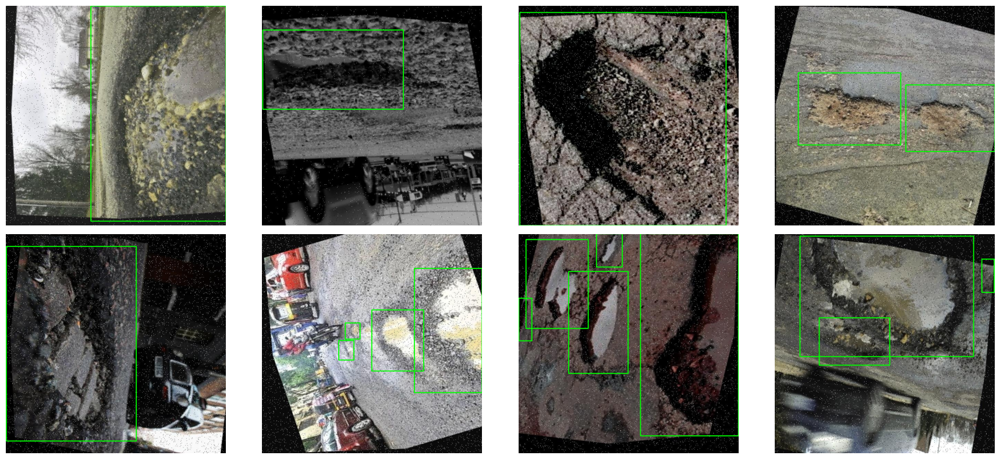

In [8]:
bad = 0
for sp in ["train", "val", "test"]:
    ims = {Path(p).stem for p in glob.glob(f"{OUT}/images/{sp}/*")}
    lbs = {Path(p).stem for p in glob.glob(f"{OUT}/labels/{sp}/*.txt")}
    assert ims == lbs, f"{sp}: image/label mismatch"
    for p in glob.glob(f"{OUT}/labels/{sp}/*.txt"):
        for l in open(p).read().strip().splitlines():
            v = list(map(float, l.split()))
            if len(v) != 5 or not all(0 <= x <= 1 for x in v[1:]) or int(v[0]) >= len(CLASS_NAMES): bad += 1
    print(sp, len(ims), "images OK")
print("Invalid label lines:", bad)

# visual check
sample = random.sample(glob.glob(f"{OUT}/images/train/*"), 8)
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, p in zip(ax.ravel(), sample):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    lp = p.replace("images", "labels").rsplit(".", 1)[0] + ".txt"
    for l in open(lp).read().strip().splitlines():
        if not l: continue
        c, xc, yc, w, h = map(float, l.split())
        cv2.rectangle(im, (int((xc-w/2)*W), int((yc-h/2)*H)), (int((xc+w/2)*W), int((yc+h/2)*H)), (0, 255, 0), 2)
    a.imshow(im); a.axis("off")
plt.tight_layout(); plt.show()

In [9]:
from ultralytics import YOLO
model = YOLO("yolo11s.pt")
results = model.train(
    data=YAML, epochs=100, imgsz=640, batch=16, patience=25, device=0, workers=2,
    optimizer="AdamW", lr0=0.001, cos_lr=True, seed=SEED, deterministic=True,
    project=f"{WORK}/runs", name="pothole_v1", plots=True,
    # Augmentation (sirf training par, online)
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,      # din/raat/shadow
    degrees=5, translate=0.1, scale=0.5, shear=2.0, perspective=0.0005,
    fliplr=0.5, flipud=0.0,                  # road ko ulta nahi karte
    mosaic=1.0, mixup=0.1, close_mosaic=10,
)
BEST = str(Path(model.trainer.save_dir) / "weights" / "best.pt")
print("Best weights:", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze

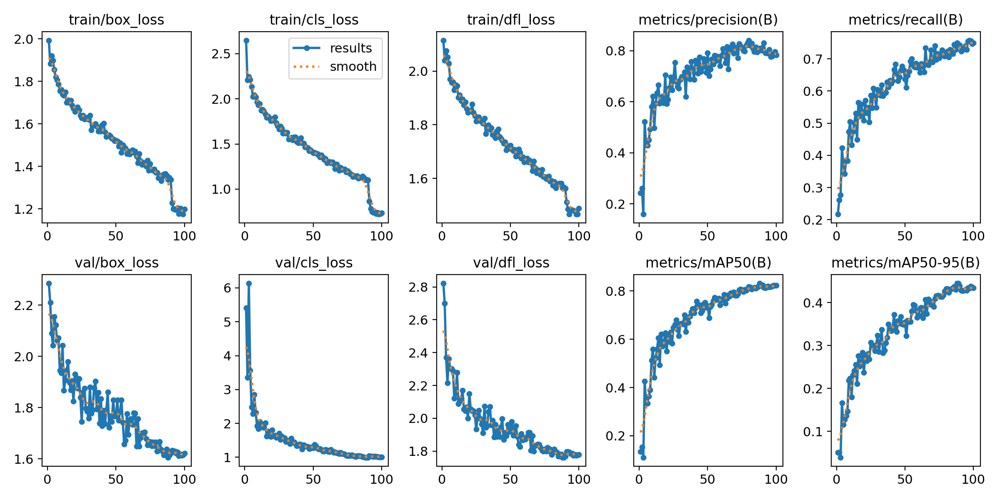

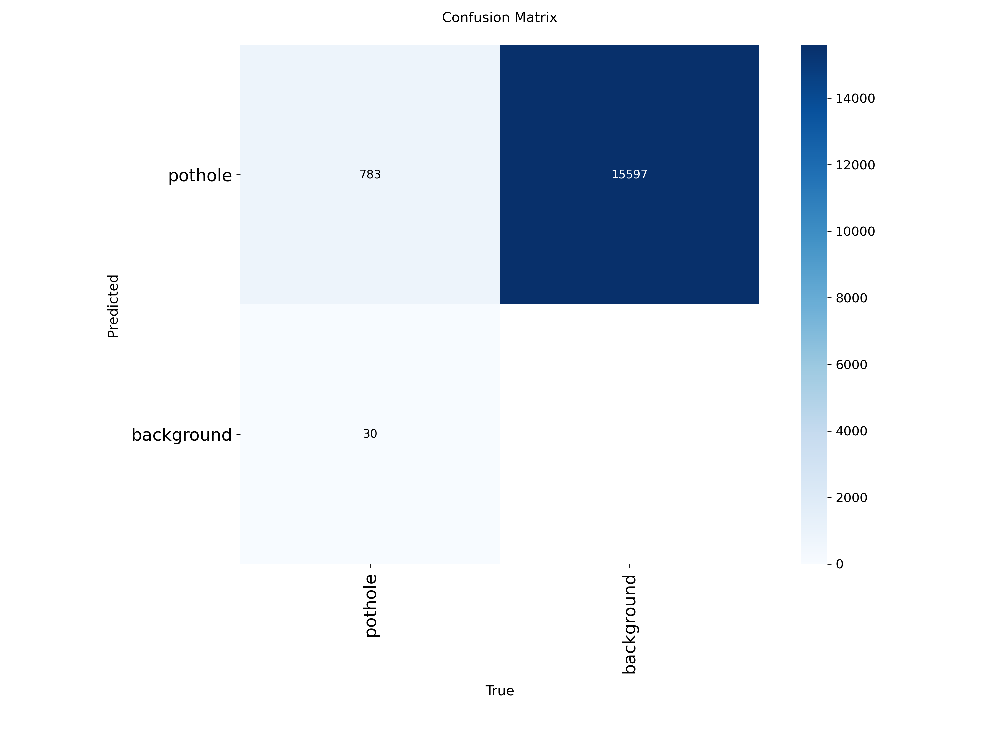

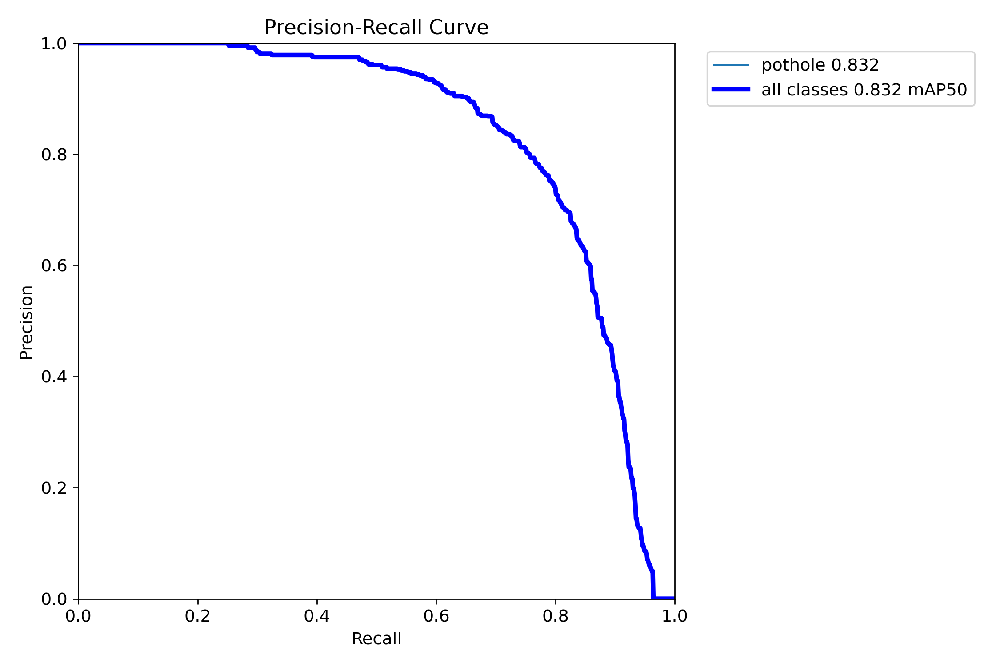

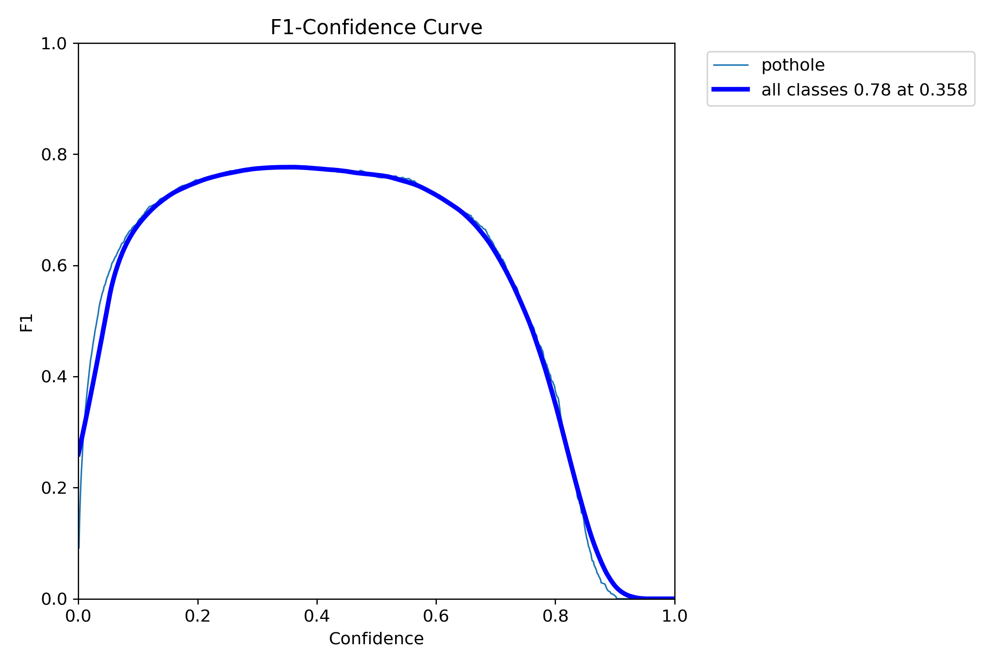

In [10]:
from IPython.display import Image as IPImage, display
sd = Path(model.trainer.save_dir)
for f in ["results.png", "confusion_matrix.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
    if (sd/f).exists(): display(IPImage(str(sd/f), width=900))

In [11]:
model = YOLO(BEST)
m = model.val(data=YAML, split="test", imgsz=640, batch=16, plots=True,
              project=f"{WORK}/runs", name="test_eval")
p, r = float(m.box.mp), float(m.box.mr)
print(f"Precision : {p:.3f}\nRecall    : {r:.3f}\nF1        : {2*p*r/(p+r+1e-9):.3f}")
print(f"mAP@0.5   : {m.box.map50:.3f}\nmAP@0.5:0.95: {m.box.map:.3f}")

try:
    BEST_CONF = float(m.box.px[m.box.f1_curve.mean(0).argmax()])
except Exception:
    BEST_CONF = 0.25
print("Recommended confidence threshold:", round(BEST_CONF, 2))

# Speed
test_imgs = sorted(glob.glob(f"{OUT}/images/test/*"))
model.predict(test_imgs[:3], verbose=False)
t = time.time(); model.predict(test_imgs[:50], imgsz=640, conf=BEST_CONF, verbose=False)
dt = (time.time()-t)/min(50, len(test_imgs)); print(f"Inference: {dt*1000:.1f} ms/img ≈ {1/dt:.1f} FPS (GPU)")

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2660.8±703.6 MB/s, size: 246.0 KB)
val: Scanning /kaggle/working/pothole_yolo/labels/test... 208 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 208/208 1.3Kit/s 0.2s
val: New cache created: /kaggle/working/pothole_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.5it/s 3.7s
                   all        208        427      0.772      0.747      0.806      0.446
Speed: 1.0ms preprocess, 12.1ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/test_eval
Precision : 0.772
Recall    : 0.747
F1        : 0.759
mAP@0.5   : 0.806
mAP@0.5:0.95: 0.446
Recommended confidence threshold: 0.35
Inference: 19.4 ms/img ≈ 51.7 FPS (GPU)


TP=311 FP=97 FN=116
             total  missed  miss_rate_%
small <1%       39      18         46.2
medium 1-5%    148      60         40.5
large >5%      240      38         15.8


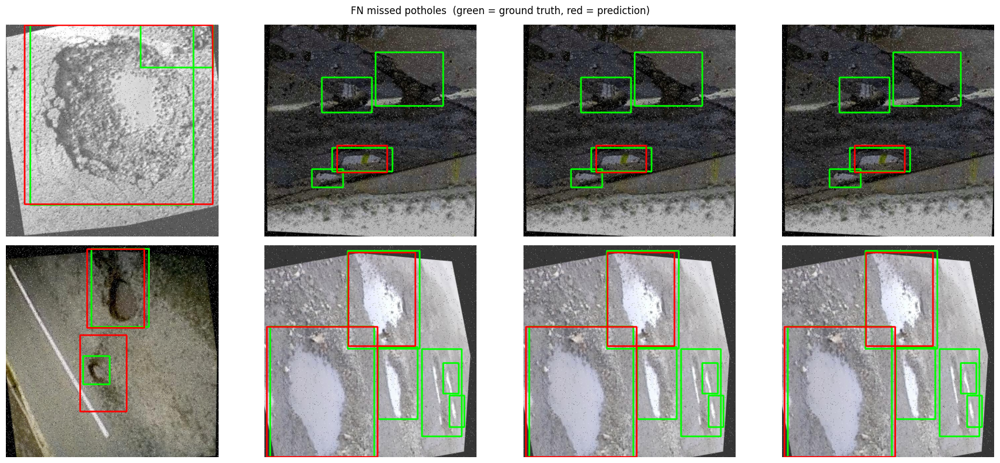

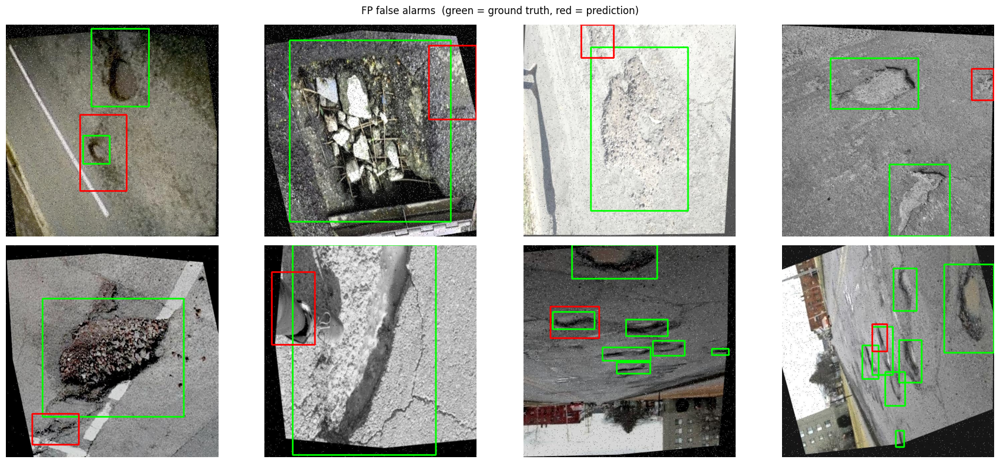

In [12]:
def iou(a, b):
    iw = max(0, min(a[2], b[2])-max(a[0], b[0])); ih = max(0, min(a[3], b[3])-max(a[1], b[1]))
    i = iw*ih; return i/((a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-i+1e-9)

TP = FP = FN = 0; fn_list, fp_list, fn_sizes, all_sizes = [], [], [], []
for ip in test_imgs:
    res = model.predict(ip, conf=BEST_CONF, imgsz=640, verbose=False)[0]
    H, W = res.orig_shape
    preds = sorted(zip(res.boxes.conf.cpu().numpy(), res.boxes.xyxy.cpu().numpy().tolist()), key=lambda x: -x[0])
    gts = []
    lp = ip.replace("images", "labels").rsplit(".", 1)[0] + ".txt"
    for l in open(lp).read().strip().splitlines():
        if l: _, xc, yc, w, h = map(float, l.split()); gts.append([(xc-w/2)*W, (yc-h/2)*H, (xc+w/2)*W, (yc+h/2)*H])
    used = set(); miss = 0
    for c, pb in preds:
        best = max(((iou(pb, g), j) for j, g in enumerate(gts) if j not in used), default=(0, -1))
        if best[0] >= 0.5: used.add(best[1]); TP += 1
        else: FP += 1; fp_list.append((ip, gts, [pb]))
    for j, g in enumerate(gts):
        ar = (g[2]-g[0])*(g[3]-g[1])/(W*H); all_sizes.append(ar)
        if j not in used:
            FN += 1; fn_sizes.append(ar); fn_list.append((ip, gts, [pb for _, pb in preds]))

print(f"TP={TP} FP={FP} FN={FN}")
bins = [0, .01, .05, 1]; labs = ["small <1%", "medium 1-5%", "large >5%"]
tab = pd.DataFrame({"total": pd.cut(all_sizes, bins, labels=labs).value_counts(),
                    "missed": pd.cut(fn_sizes, bins, labels=labs).value_counts()})
tab["miss_rate_%"] = (100*tab.missed/tab.total).round(1); print(tab)

def grid(items, title, n=8):
    items = items[:n]
    if not items: print("No", title); return
    fig, ax = plt.subplots(2, 4, figsize=(18, 8))
    for a in ax.ravel(): a.axis("off")
    for a, (ip, gts, pbs) in zip(ax.ravel(), items):
        im = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
        for g in gts: cv2.rectangle(im, tuple(map(int, g[:2])), tuple(map(int, g[2:])), (0, 255, 0), 3)   # GT green
        for q in pbs: cv2.rectangle(im, tuple(map(int, q[:2])), tuple(map(int, q[2:])), (255, 0, 0), 3)   # Pred red
        a.imshow(im)
    plt.suptitle(f"{title}  (green = ground truth, red = prediction)"); plt.tight_layout()
    plt.savefig(f"{WORK}/{title.split()[0]}_examples.png", dpi=110); plt.show()

grid(fn_list, "FN missed potholes"); grid(fp_list, "FP false alarms")

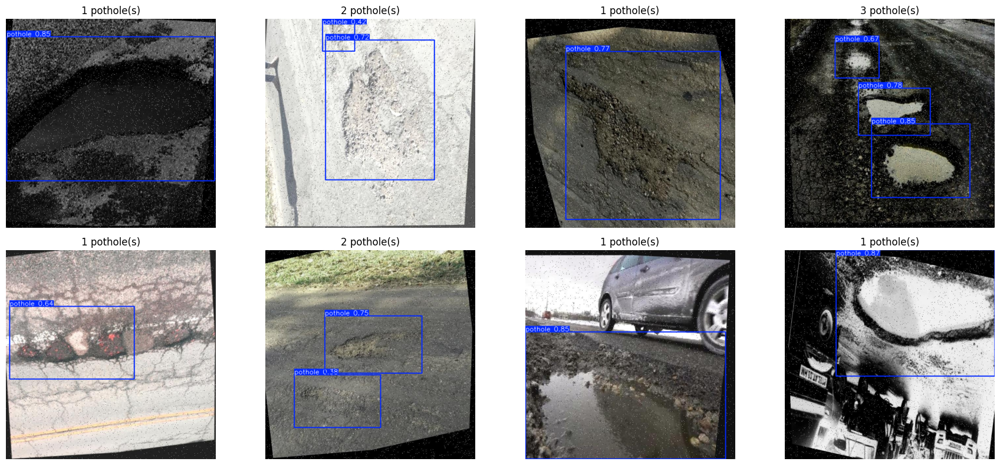

In [13]:
sample = random.sample(test_imgs, min(8, len(test_imgs)))
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, ip in zip(ax.ravel(), sample):
    r = model.predict(ip, conf=BEST_CONF, imgsz=640, verbose=False)[0]
    a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.set_title(f"{len(r.boxes)} pothole(s)"); a.axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/test_predictions.png", dpi=110); plt.show()

In [14]:
shutil.copy(BEST, f"{WORK}/best.pt")
try: model.export(format="onnx", imgsz=640, simplify=True)   # optional, CPU laptop par fast
except Exception as e: print("ONNX skipped:", e)
shutil.make_archive(f"{WORK}/pothole_results", "zip", str(sd))
print(os.listdir(WORK))

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/pothole_v1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 355ms
 Downloaded onnxruntime
Prepared 2 packages in 348ms
Installed 2 packages in 10ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: 